In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

In [3]:
# ============================================================
# 1. LOAD EMBEDDINGS
# ============================================================

EMBEDDINGS_DIR = Path("../matsne_data/embeddings")

QUESTIONS_FILE = EMBEDDINGS_DIR / "eval_questions_bge_m3.jsonl"
CHILDREN_FILE = EMBEDDINGS_DIR / "children_bge_m3.jsonl"


def load_jsonl(path):
    with path.open("r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]


questions = load_jsonl(QUESTIONS_FILE)
children = load_jsonl(CHILDREN_FILE)

print(f"Questions: {len(questions):,}")
print(f"Children:  {len(children):,}")

Questions: 200
Children:  14,715


In [4]:
# ============================================================
# 2. INSPECT DATA
# ============================================================

questions_df = pd.DataFrame(questions)
children_df = pd.DataFrame(children)

print("\nQuestion columns:")
print(questions_df.columns.tolist())

print("\nChild columns:")
print(children_df.columns.tolist())


Question columns:
['question', 'type', 'doc_id', 'source_parent', 'source_child', 'evidence', 'answer', 'batch', 'embedding']

Child columns:
['child_id', 'parent_id', 'doc_id', 'kind', 'text', 'retrieval_text', 'embedding']


In [5]:
# ============================================================
# 3. CHECK EMBEDDING DIMENSIONS
# ============================================================

question_dims = questions_df["embedding"].apply(len)
child_dims = children_df["embedding"].apply(len)

print("\nEmbedding dimensions:")
print(f"Question embeddings: {question_dims.unique()}")
print(f"Child embeddings:    {child_dims.unique()}")

assert question_dims.nunique() == 1
assert child_dims.nunique() == 1
assert question_dims.iloc[0] == child_dims.iloc[0]

EMBEDDING_DIM = question_dims.iloc[0]

print(f"\nEmbedding dimension: {EMBEDDING_DIM}")


Embedding dimensions:
Question embeddings: [1024]
Child embeddings:    [1024]

Embedding dimension: 1024


In [6]:
# ============================================================
# 4. CHECK EMBEDDING NORMALIZATION
# ============================================================

question_embeddings = np.array(
    questions_df["embedding"].tolist(),
    dtype=np.float32,
)

child_embeddings = np.array(
    children_df["embedding"].tolist(),
    dtype=np.float32,
)

question_norms = np.linalg.norm(question_embeddings, axis=1)
child_norms = np.linalg.norm(child_embeddings, axis=1)

print("\nEmbedding norms:")

print(
    f"Questions: "
    f"min={question_norms.min():.6f}, "
    f"mean={question_norms.mean():.6f}, "
    f"max={question_norms.max():.6f}"
)

print(
    f"Children:  "
    f"min={child_norms.min():.6f}, "
    f"mean={child_norms.mean():.6f}, "
    f"max={child_norms.max():.6f}"
)

print("\nReady for similarity search.")


Embedding norms:
Questions: min=1.000000, mean=1.000000, max=1.000000
Children:  min=1.000000, mean=1.000000, max=1.000000

Ready for similarity search.


# Questions df

In [11]:
# ============================================================
# QUESTION DATASET ANALYSIS
# ============================================================

print("NUMBER OF QUESTIONS")
print("-------------------")
print(f"Total questions: {len(questions_df):,}")


# ------------------------------------------------------------
# Questions by type
# ------------------------------------------------------------

print("\nQUESTIONS BY TYPE")
print("-----------------")

questions_by_type = (
    questions_df["type"]
    .value_counts(dropna=False)
    .rename_axis("type")
    .reset_index(name="n_questions")
)

questions_by_type["percentage"] = (
    questions_by_type["n_questions"] / len(questions_df) * 100
)

display(questions_by_type)


# ------------------------------------------------------------
# Unique source parents / children
# ------------------------------------------------------------

print("\nSOURCE COUNTS")
print("-------------")

n_source_parents = questions_df["source_parent"].nunique(dropna=True)
n_source_children = questions_df["source_child"].nunique(dropna=True)
n_documents = questions_df["doc_id"].nunique(dropna=True)

print(f"Unique documents:       {n_documents:,}")
print(f"Unique source parents:  {n_source_parents:,}")
print(f"Unique source children:  {n_source_children:,}")

NUMBER OF QUESTIONS
-------------------
Total questions: 200

QUESTIONS BY TYPE
-----------------


,type,n_questions,percentage
0,factual lookup,38,19.0
1,conditions/requirements,38,19.0
2,date/effective period,35,17.5
3,multi-child,27,13.5
4,responsibility/authority,18,9.0
5,multi-parent,16,8.0
6,procedure,11,5.5
7,multi-document,10,5.0
8,comparison,7,3.5



SOURCE COUNTS
-------------
Unique documents:       82
Unique source parents:  165
Unique source children:  183


In [13]:
print("SOURCE ID COUNTS PER QUESTION")
print("============================")

total = len(questions_df)

for col, label in [
    ("n_docs", "document"),
    ("n_parents", "parent"),
    ("n_children", "child"),
]:
    single = (questions_df[col] == 1).sum()
    multiple = (questions_df[col] > 1).sum()

    print(f"\n{label.upper()}:")
    print(f"Single {label}:   {single:,} ({single / total * 100:.0f}%)")
    print(f"Multiple {label}: {multiple:,} ({multiple / total * 100:.0f}%)")

SOURCE ID COUNTS PER QUESTION

DOCUMENT:
Single document:   188 (94%)
Multiple document: 12 (6%)

PARENT:
Single parent:   172 (86%)
Multiple parent: 28 (14%)

CHILD:
Single child:   150 (75%)
Multiple child: 50 (25%)


In [16]:
import numpy as np


# Question × child similarity matrix
similarities = question_embeddings @ child_embeddings.T

# Document ID for every child
child_doc_ids = children_df["doc_id"].astype(str).values

# Gold documents for every question
gold_docs = (
    questions_df["doc_id"]
    .fillna("")
    .astype(str)
    .apply(lambda x: {i.strip() for i in x.split(";") if i.strip()})
    .tolist()
)


def calculate_recall_at_k(k):
    single_recalls = []
    multiple_recalls = []
    overall_recalls = []

    for i, gold in enumerate(gold_docs):

        if not gold:
            continue

        # Top-k retrieved children
        top_k_indices = np.argsort(-similarities[i])[:k]

        # Documents represented by retrieved children
        retrieved_docs = set(child_doc_ids[top_k_indices])

        # Fraction of gold documents retrieved
        recall = len(gold & retrieved_docs) / len(gold)

        overall_recalls.append(recall)

        if len(gold) == 1:
            single_recalls.append(recall)
        else:
            multiple_recalls.append(recall)

    return {
        "single_doc": np.mean(single_recalls),
        "multiple_doc": np.mean(multiple_recalls),
        "overall": np.mean(overall_recalls),
    }


# Calculate Recall@k
results = []

for k in [1, 3, 5, 10, 20, 50]:
    recalls = calculate_recall_at_k(k)

    results.append({
        "k": k,
        "single_doc": recalls["single_doc"] * 100,
        "multiple_doc": recalls["multiple_doc"] * 100,
        "overall": recalls["overall"] * 100,
    })

recall_df = pd.DataFrame(results)

# Display as percentages with no decimals
display(
    recall_df.style
    .format({
        "single_doc": "{:.0f}%",
        "multiple_doc": "{:.0f}%",
        "overall": "{:.0f}%",
    })
)

,k,single_doc,multiple_doc,overall
0,1,77%,38%,74%
1,3,87%,75%,86%
2,5,90%,83%,90%
3,10,95%,92%,94%
4,20,97%,96%,97%
5,50,99%,100%,99%


In [17]:
# Parent ID for every child
child_parent_ids = children_df["parent_id"].astype(str).values

# Gold parents for every question
gold_parents = (
    questions_df["source_parent"]
    .fillna("")
    .astype(str)
    .apply(lambda x: {i.strip() for i in x.split(";") if i.strip()})
    .tolist()
)


def calculate_parent_recall_at_k(k):
    single_recalls = []
    multiple_recalls = []
    overall_recalls = []

    for i, gold in enumerate(gold_parents):

        if not gold:
            continue

        # Top-k retrieved children
        top_k_indices = np.argsort(-similarities[i])[:k]

        # Parents represented by retrieved children
        retrieved_parents = set(child_parent_ids[top_k_indices])

        # Fraction of gold parents retrieved
        recall = len(gold & retrieved_parents) / len(gold)

        overall_recalls.append(recall)

        if len(gold) == 1:
            single_recalls.append(recall)
        else:
            multiple_recalls.append(recall)

    return {
        "single_parent": np.mean(single_recalls),
        "multiple_parent": np.mean(multiple_recalls),
        "overall": np.mean(overall_recalls),
    }


# Calculate Parent Recall@k
parent_results = []

for k in [1, 3, 5, 10, 20, 50]:
    recalls = calculate_parent_recall_at_k(k)

    parent_results.append({
        "k": k,
        "single_parent": recalls["single_parent"] * 100,
        "multiple_parent": recalls["multiple_parent"] * 100,
        "overall": recalls["overall"] * 100,
    })

parent_recall_df = pd.DataFrame(parent_results)

display(
    parent_recall_df.style
    .format({
        "single_parent": "{:.0f}%",
        "multiple_parent": "{:.0f}%",
        "overall": "{:.0f}%",
    })
)

,k,single_parent,multiple_parent,overall
0,1,60%,36%,57%
1,3,78%,66%,77%
2,5,83%,70%,81%
3,10,90%,80%,89%
4,20,92%,93%,92%
5,50,95%,95%,95%


In [19]:
# Child ID for every embedded child
child_ids = children_df["child_id"].astype(str).values

# Gold children for every question
gold_children = (
    questions_df["source_child"]
    .fillna("")
    .astype(str)
    .apply(lambda x: {i.strip() for i in x.split(";") if i.strip()})
    .tolist()
)


def calculate_child_recall_at_k(k):
    single_recalls = []
    multiple_recalls = []
    overall_recalls = []

    for i, gold in enumerate(gold_children):

        if not gold:
            continue

        # Top-k retrieved children
        top_k_indices = np.argsort(-similarities[i])[:k]

        # Retrieved child IDs
        retrieved_children = set(child_ids[top_k_indices])

        # Fraction of gold children retrieved
        recall = len(gold & retrieved_children) / len(gold)

        overall_recalls.append(recall)

        if len(gold) == 1:
            single_recalls.append(recall)
        else:
            multiple_recalls.append(recall)

    return {
        "single_child": np.mean(single_recalls),
        "multiple_child": np.mean(multiple_recalls),
        "overall": np.mean(overall_recalls),
    }


# Calculate Child Recall@k
child_results = []

for k in [1, 3, 5, 10, 20, 50]:
    recalls = calculate_child_recall_at_k(k)

    child_results.append({
        "k": k,
        "single_child": recalls["single_child"] * 100,
        "multiple_child": recalls["multiple_child"] * 100,
        "overall": recalls["overall"] * 100,
    })

child_recall_df = pd.DataFrame(child_results)

display(
    child_recall_df.style
    .format({
        "single_child": "{:.0f}%",
        "multiple_child": "{:.0f}%",
        "overall": "{:.0f}%",
    })
)

,k,single_child,multiple_child,overall
0,1,51%,29%,46%
1,3,73%,58%,70%
2,5,77%,70%,76%
3,10,87%,80%,86%
4,20,89%,88%,89%
5,50,93%,91%,92%


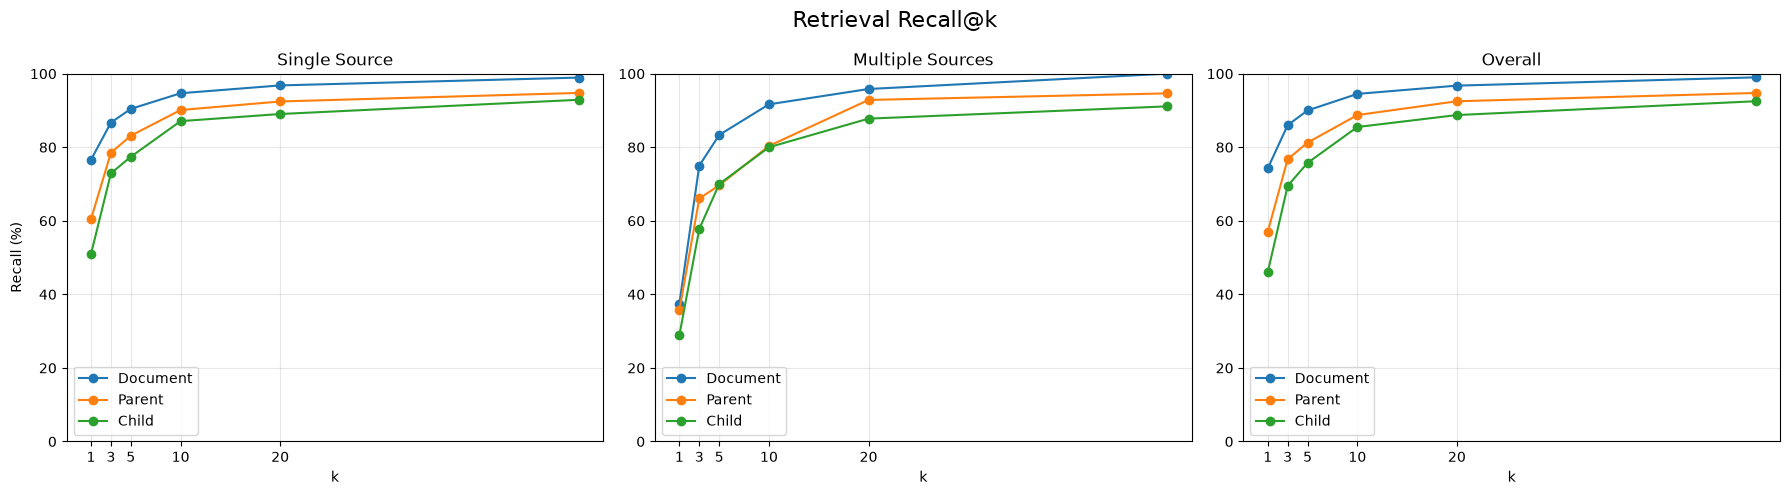

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Data
levels = {
    "Document": recall_df,
    "Parent": parent_recall_df,
    "Child": child_recall_df,
}

# 1. Single
ax = axes[0]

for name, df in levels.items():
    ax.plot(
        df["k"],
        df.iloc[:, 1],
        marker="o",
        label=name
    )

ax.set_title("Single Source")
ax.set_xlabel("k")
ax.set_ylabel("Recall (%)")
ax.set_xticks([1, 3, 5, 10, 20])
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)
ax.legend()


# 2. Multiple
ax = axes[1]

for name, df in levels.items():
    ax.plot(
        df["k"],
        df.iloc[:, 2],
        marker="o",
        label=name
    )

ax.set_title("Multiple Sources")
ax.set_xlabel("k")
ax.set_xticks([1, 3, 5, 10, 20])
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)
ax.legend()


# 3. Overall
ax = axes[2]

for name, df in levels.items():
    ax.plot(
        df["k"],
        df.iloc[:, 3],
        marker="o",
        label=name
    )

ax.set_title("Overall")
ax.set_xlabel("k")
ax.set_xticks([1, 3, 5, 10, 20])
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)
ax.legend()


fig.suptitle("Retrieval Recall@k", fontsize=16)
plt.tight_layout()
plt.show()

ეხლა აქიდან რა დავინახე: თუ მომაქვს ტოპ 20 დოკუმენტი რექოლის ქეფი არის 97%, ჩაილდებით და მშობლებით 89 და 92. ამიტომ რერანკერს ვტესტავ.

In [22]:
# ============================================================
# TEST: EFFECT OF per_doc ON PARENT-LEVEL RETRIEVAL RECALL
# ============================================================

# Same parameters as the actual RAG pipeline
BUDGET_TOKENS = 12000
CPT = 1.8
CAP_CHARS = 6000
DEPTH = 200

PER_DOC_VALUES = [1, 2, 3, 5, 10, None]


# ------------------------------------------------------------
# Parent information
# ------------------------------------------------------------

PARENTS_FILE = Path("../matsne_data/chunks/parents.jsonl")

parents = load_jsonl(PARENTS_FILE)

parents_dict = {
    p["parent_id"]: p
    for p in parents
}

# Parent length, exactly as in Corpus
parent_lengths = {
    pid: len(p.get("text", ""))
    for pid, p in parents_dict.items()
}

# Child -> parent
child_parent_ids = (
    children_df["parent_id"]
    .astype(str)
    .values
)

# Child -> document
child_doc_ids = (
    children_df["doc_id"]
    .astype(str)
    .values
)

# Child IDs, used when ordering children inside a capped parent
child_ids = (
    children_df["child_id"]
    if "child_id" in children_df.columns
    else children_df["chunk_id"]
)

child_ids = child_ids.astype(str).values


# ------------------------------------------------------------
# Gold parents for every question
# ------------------------------------------------------------

gold_parents = (
    questions_df["source_parent"]
    .fillna("")
    .astype(str)
    .apply(
        lambda x: {
            i.strip()
            for i in x.split(";")
            if i.strip()
        }
    )
    .tolist()
)


# ------------------------------------------------------------
# Function reproducing Corpus.assemble()
# ------------------------------------------------------------

def assemble_parent_ids(
    ranked_indices,
    budget_tokens=BUDGET_TOKENS,
    cap_chars=CAP_CHARS,
    per_doc=3,
    cpt=CPT,
    depth=DEPTH,
):
    budget_chars = budget_tokens * cpt

    included = {}
    doc_counts = {}
    used = 0

    for ci in ranked_indices[:depth]:

        pid = child_parent_ids[ci]
        did = child_doc_ids[ci]

        # Already selected this parent
        if pid in included:
            p = included[pid]

            # Oversized parent:
            # allow a second matched child
            if (
                p["capped"]
                and len(p["kids"]) < 2
                and ci not in p["kids"]
                and used + len(
                    children_df.iloc[ci]["text"]
                ) <= budget_chars
            ):
                p["kids"].append(ci)

                used += len(
                    children_df.iloc[ci]["text"]
                )

            continue

        # Per-document parent limit
        if (
            per_doc is not None
            and doc_counts.get(did, 0) >= per_doc
        ):
            continue

        # Full parent length
        full = parent_lengths.get(
            pid,
            len(children_df.iloc[ci]["text"]),
        )

        capped = (
            bool(cap_chars)
            and full > cap_chars
        )

        cost = (
            len(children_df.iloc[ci]["text"])
            if capped
            else full
        )

        # Context budget exhausted
        if used + cost > budget_chars:
            continue

        included[pid] = {
            "capped": capped,
            "kids": [ci],
            "doc": did,
        }

        doc_counts[did] = (
            doc_counts.get(did, 0) + 1
        )

        used += cost

    return list(included.keys()), used / cpt


# ------------------------------------------------------------
# Run experiment
# ------------------------------------------------------------

results = []

for per_doc in PER_DOC_VALUES:

    recalls = []
    n_gold_retrieved = []
    n_gold_total = []

    for i, gold in enumerate(gold_parents):

        if not gold:
            continue

        # Same ranking used by the real RAG system
        ranked = np.argsort(
            -similarities[i]
        )

        retrieved_parents, context_tokens = (
            assemble_parent_ids(
                ranked,
                per_doc=per_doc,
            )
        )

        retrieved_parents = set(
            retrieved_parents
        )

        recall = (
            len(gold & retrieved_parents)
            / len(gold)
        )

        recalls.append(recall)
        n_gold_retrieved.append(
            len(gold & retrieved_parents)
        )
        n_gold_total.append(len(gold))

    results.append(
        {
            "per_doc": (
                "unlimited"
                if per_doc is None
                else per_doc
            ),
            "parent_recall": np.mean(recalls) * 100,
            "questions": len(recalls),
            "gold_parents_retrieved": sum(
                n_gold_retrieved
            ),
            "gold_parents_total": sum(
                n_gold_total
            ),
        }
    )


per_doc_recall_df = pd.DataFrame(results)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nPARENT-LEVEL RETRIEVAL RECALL")
print("-----------------------------")

display(
    per_doc_recall_df.style.format(
        {
            "parent_recall": "{:.2f}%",
        }
    )
)


PARENT-LEVEL RETRIEVAL RECALL
-----------------------------


,per_doc,parent_recall,questions,gold_parents_retrieved,gold_parents_total
0,1,74.75%,200,165,228
1,2,85.00%,200,192,228
2,3,88.00%,200,200,228
3,5,88.75%,200,202,228
4,10,88.75%,200,202,228
5,unlimited,88.75%,200,202,228


## Retrieval → LLM Context Logic

1. Embed the question with precomputed BGE-M3 and rank **child chunks** by similarity.
2. Consider the top **200 children**.
3. Walk through them in similarity order and select their **parent chunks**:
   - If a parent is ≤ **6,000 characters**, include the **whole parent**.
   - If a parent is > 6,000 characters, include only the **1–2 highest-ranked matching children**.
4. Allow at most **10 parents per document** (`per_doc=10`).
5. Stop when the context reaches approximately **12,000 tokens** (`cpt=1.8`).
6. For every selected parent, add a header containing its **parent ID, breadcrumb/title, effective date, and expiration date**.
7. The LLM receives these assembled parent passages + headers, followed by the question.

**In short:**  
`Question → BGE-M3 → child ranking → parent selection → whole parent or matched children → max 3 parents/document → ~12k-token context → LLM`